# Cut-site prediction: ESM3Di vs base ESM++ embeddings (raw features)

Sensitivity check for `cutsite_esm3di_vs_esmpp_standardised.ipynb`, which is the source of
Figure 2d. Identical in every respect except that the embeddings are fed to the classifier
as they come, without the per-dimension z-score.

This is the preprocessing the shipped `esm3di cutting` pipeline uses, so it answers whether
the conclusion depends on the standardisation step. Section 4 puts the two side by side.

| | |
|---|---|
| Dataset | 86 ICTV-annotated polyprotein records, four genera |
| Labels | `FT SITE` features annotated `/note="Cleavage"`; records without annotation excluded |
| Split | leave-one-genus-out, whole sequences |
| Embeddings | 1024-residue windows, 128 overlap, as `ESM3DiPredictor` computes them |
| Features | raw |
| Head | FFN 256→128, dropout 0.45/0.10, AdamW lr 1e-3 wd 3e-4, batch 2048, 12 epochs |
| Seeds | 1–10 |

**Reproducibility.** `--fast-loader` keeps the training fold on the GPU instead of streaming
it through a `DataLoader`. It trains the same model about 25x faster, but draws its batch
order from the device RNG, so results are statistically equivalent to the default path
rather than bit-identical.

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path

import pandas as pd

HERE     = Path.cwd()                                        # .../polyprotein_cut
SCRIPTS  = HERE / "scripts"
RESULTS  = HERE / "results" / "esm3di_vs_esmpp_raw"           # small artefacts, kept in the repo
STDRUN   = HERE / "results" / "esm3di_vs_esmpp_standardised"  # the same run with --standardise
SEEDS    = "1,2,3,4,5,6,7,8,9,10"
EPOCHS   = "12"
N_FITS   = 4 * 2 * len(SEEDS.split(","))   # genera x arms x seeds

# Everything heavy is rebuilt from scratch on every run of this notebook, so that running
# it top to bottom reproduces the result rather than reading back an earlier one.
# FRESH=0 reuses the run directory, for iterating on the figures alone.
FRESH   = os.environ.get("CUTSITE_FRESH", "1") == "1"
SCRATCH = Path(os.environ.get("CUTSITE_SCRATCH", f"/scratch/{os.environ['USER']}/cutsite_raw"))
RUN, CACHE  = SCRATCH / "run", SCRATCH / "embeddings"
PREDICTIONS = RUN / "oof_ffn_predictions.csv"          # ~200 MB: stays on scratch

for d in (RUN, CACHE, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
# The clearing happens in the run cell, not here, so that opening this notebook and
# initialising the paths cannot destroy a completed run.

sys.path.insert(0, str(SCRIPTS))
print(f"fresh run: {FRESH}")
print("scripts  ", SCRIPTS)
print("run dir  ", RUN)
print("cache    ", CACHE)
print("results  ", RESULTS)

fresh run: True
scripts   /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/scripts
run dir   /scratch/fweikert/cutsite_raw/run
cache     /scratch/fweikert/cutsite_raw/embeddings
results   /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp_raw


## 1. Environment

`run_comparison.py` uses scikit-learn for ROC AUC and average precision. A GPU is needed for
the embeddings (~20 s per arm); with `--fast-loader` the head training is roughly 1 s per
genus × arm × seed instead of ~15 s.

In [2]:
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
import sklearn
print("scikit-learn", sklearn.__version__)

torch 2.14.1+cu130 | cuda: True NVIDIA A100-PCIE-40GB MIG 3g.20gb


scikit-learn 1.9.1


## 2. The ESM3Di checkpoint

The run uses the published PEFT adapter from the Hugging Face repo, resolved cache-first
exactly as `src/esm3di/inference/predictor.py` does.

The earlier single-seed run used a local `esm3di_from_mlm/epoch_5.pt` (sha256 `4e8143a4…`)
that is not on this machine. The two could not be shown equivalent, because re-running one
seed moves even the unchanged base arm by up to 0.025. Results here are internally
consistent but are **not** directly comparable with `results/esm3di_vs_esmpp/`.

In [3]:
from huggingface_hub import snapshot_download

def resolve_adapter(repo_id="cactuskid13/ESM3di_Small_MLM_3di", revision=None):
    patterns = ["hf_compatible", "hf_compatible/**"]
    try:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=patterns, local_files_only=True)
    except Exception:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=patterns, local_files_only=False)
    return Path(root) / "hf_compatible"

ADAPTER = resolve_adapter()
print("adapter", ADAPTER)
print(json.load(open(ADAPTER / "adapter_config.json"))["base_model_name_or_path"],
      "| r, alpha, dropout:",
      *[json.load(open(ADAPTER / "adapter_config.json"))[k] for k in ("r", "lora_alpha", "lora_dropout")])

adapter /users/fweikert/.cache/huggingface/hub/models--cactuskid13--ESM3di_Small_MLM_3di/snapshots/b32e8d308efd435be015122d7a1ca8f2dc671e86/hf_compatible
Synthyra/ESMplusplus_small | r, alpha, dropout: 16 32.0 0.01


## 3. Run the comparison

Extracts per-residue embeddings for both arms and trains the head for every
genus × arm × seed: 4 genera × 2 arms × 10 seeds = 80 fits. Nothing is reused — the run directory and the
embedding cache are cleared first.

In [4]:
if FRESH:
    for d in (RUN, CACHE):                 # no cached embeddings, no partial metrics
        if d.exists():
            shutil.rmtree(d)
        d.mkdir(parents=True, exist_ok=True)
    print("cleared the run directory and the embedding cache\n")

cmd = [sys.executable, str(SCRIPTS / "run_comparison.py"),
       "--adapter", str(ADAPTER), "--seeds", SEEDS, "--architectures", "ffn",
       "--epochs", EPOCHS, "--fast-loader",
       "--cache-dir", str(CACHE), "--output-dir", str(RUN)]
print(" ".join(cmd), "\n", flush=True)

t0 = time.time()
noise = ("Loading weights", "Attention backend", "UserWarning", "torch.from_numpy",
         "warnings.warn", "  x = torch")
with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1) as proc:
    for line in proc.stdout:
        if not any(n in line for n in noise):
            print(line.rstrip(), flush=True)
if proc.returncode:
    raise RuntimeError(f"run_comparison.py exited {proc.returncode}")
print(f"\nembeddings + {N_FITS} head trainings in {(time.time() - t0) / 60:.1f} min")

cleared the run directory and the embedding cache

/scratch/fweikert/envs/esm3di-test/bin/python /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/scripts/run_comparison.py --adapter /users/fweikert/.cache/huggingface/hub/models--cactuskid13--ESM3di_Small_MLM_3di/snapshots/b32e8d308efd435be015122d7a1ca8f2dc671e86/hf_compatible --seeds 1,2,3,4,5,6,7,8,9,10 --architectures ffn --epochs 12 --fast-loader --cache-dir /scratch/fweikert/cutsite_raw/embeddings --output-dir /scratch/fweikert/cutsite_raw/run 



Dataset groups: {'Hepacivirus-CHH': 15, 'Orthoflavivirus-CHH': 31, 'Pegivirus-CHH': 21, 'Pestivirus-CHH': 19}


Annotated proteins: 86 residues: 287411 cut sites: 800 device: cuda


esm3di: 1/86 sequences, 0.5s


esm3di: 5/86 sequences, 1.5s


esm3di: 9/86 sequences, 2.4s


... (130 outputs left out)

     Pestivirus-CHH           esm3di          ffn      0.866388        0.181624             0.172712             0.170888                  0.384737    0.012017      0.019691           0.013718           0.009472                0.028134                19               193            0.002611            73906


     Pestivirus-CHH       esmpp_base          ffn      0.848543        0.245382             0.164243             0.150202                  0.351196    0.006640      0.011047           0.013283           0.010750                0.016885                19               193            0.002611            73906


Wrote /scratch/fweikert/cutsite_raw/run



embeddings + 80 head trainings in 4.8 min


### Keep the small artefacts in the repository

Everything except the predictions file is a few kB.

In [5]:
for name in ("seed_metrics.csv", "summary.csv", "run_metadata.json"):
    src = RUN / name
    if src.exists():
        shutil.copy2(src, RESULTS / name); print("copied", name)

met = pd.read_csv(RESULTS / "seed_metrics.csv"); met = met[met.architecture == "ffn"]
assert len(met) == N_FITS, f"expected {N_FITS} rows, found {len(met)}"
print(f"\n{len(met)} rows | seeds {sorted(met.seed.unique())} | "
      f"genera {sorted(met.heldout_group.unique())}")
meta = json.load(open(RESULTS / "run_metadata.json"))
print(f"fast_loader={meta['fast_loader']} | epochs={meta['heads']['ffn']['epochs']} | "
      f"batch={meta['ffn_batch_size']}")

copied seed_metrics.csv
copied summary.csv
copied run_metadata.json

80 rows | seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | genera ['Hepacivirus-CHH', 'Orthoflavivirus-CHH', 'Pegivirus-CHH', 'Pestivirus-CHH']
fast_loader=True | epochs=12 | batch=2048


## 4. Results

ROC AUC per held-out genus, and the paired within-seed difference. Both arms share each
seed, so they get identical head initialisation, dropout masks and batch order; the paired
difference therefore isolates the effect of the embeddings.

In [6]:
import numpy as np

print("ROC AUC, mean +/- sd over seeds\n")
print(f"{'genus':22s}{'ESM++ base':>18s}{'ESM3Di':>18s}{'delta':>9s}{'  seeds won'}")
per_genus = []
for g, s in met.groupby("heldout_group"):
    b = s[s.embedding_source == "esmpp_base"].set_index("seed").roc_auc.sort_index()
    e = s[s.embedding_source == "esm3di"].set_index("seed").roc_auc.sort_index()
    d = (e - b).dropna(); per_genus.append(d.mean())
    print(f"{g:22s}{b.mean():11.4f}±{b.std():.4f}{e.mean():11.4f}±{e.std():.4f}"
          f"{d.mean():+9.4f}   {(d > 0).sum()}/{len(d)}")
per_genus = np.array(per_genus)
print(f"\nmean over genera {per_genus.mean():+.4f}  sd {per_genus.std(ddof=1):.4f}  "
      f"genera won {(per_genus > 0).sum()}/4")
print("\nThe generalisation unit is the genus, so n = 4; the per-seed spread describes "
      "retraining noise, not sampling over viruses.")

ROC AUC, mean +/- sd over seeds

genus                         ESM++ base            ESM3Di    delta  seeds won
Hepacivirus-CHH            0.8487±0.0114     0.8686±0.0069  +0.0199   10/10
Orthoflavivirus-CHH        0.8725±0.0109     0.8943±0.0085  +0.0217   10/10
Pegivirus-CHH              0.8157±0.0086     0.8597±0.0098  +0.0441   10/10
Pestivirus-CHH             0.8485±0.0066     0.8664±0.0120  +0.0178   10/10

mean over genera +0.0259  sd 0.0122  genera won 4/4

The generalisation unit is the genus, so n = 4; the per-seed spread describes retraining noise, not sampling over viruses.


In [7]:
# Standardised against raw features: same dataset, same seeds, one option apart.
def fold_means(path):
    d = pd.read_csv(path / "seed_metrics.csv")
    d = d[(d.architecture == "ffn") & (d.seed.isin(met.seed.unique()))]
    return d.groupby(["heldout_group", "embedding_source"]).roc_auc.mean().unstack()

runs = {"raw features": RESULTS, "standardised features": STDRUN}
runs = {k: v for k, v in runs.items() if (v / "seed_metrics.csv").exists()}

table = {}
for name, path in runs.items():
    f = fold_means(path)
    table[(name, "base")] = f.esmpp_base
    table[(name, "ESM3Di")] = f.esm3di
    table[(name, "delta")] = f.esm3di - f.esmpp_base
out = pd.DataFrame(table)
out.columns = pd.MultiIndex.from_tuples(out.columns)
print(out.round(4).to_string())
print()
for name in runs:
    print(f"{name:24s} mean delta over genera {out[(name, 'delta')].mean():+.4f}  "
          f"genera won {(out[(name, 'delta')] > 0).sum()}/4")
print("\nThe two differ only in --standardise; retraining noise for this task "
      "is ~0.01-0.02 ROC AUC per genus.")

                    raw features                 standardised features                
                            base  ESM3Di   delta                  base  ESM3Di   delta
heldout_group                                                                         
Hepacivirus-CHH           0.8487  0.8686  0.0199                0.8449  0.8666  0.0217
Orthoflavivirus-CHH       0.8725  0.8943  0.0217                0.8854  0.9128  0.0273
Pegivirus-CHH             0.8157  0.8597  0.0441                0.8273  0.8838  0.0564
Pestivirus-CHH            0.8485  0.8664  0.0178                0.8347  0.8985  0.0638

raw features             mean delta over genera +0.0259  genera won 4/4
standardised features    mean delta over genera +0.0423  genera won 4/4

The two differ only in --standardise; retraining noise for this task is ~0.01-0.02 ROC AUC per genus.


## 5. Figures and tables

`make_paper_figures.py` writes Fig. 2d plus the alternative panels and the supplementary
outputs into `RESULTS`. It asserts that the inset table stays below the identity line and
that the legend covers no curve, so a later restyle fails loudly rather than silently
overlapping.

In [8]:
cmd = [sys.executable, str(SCRIPTS / "make_paper_figures.py"),
       "--results-dir", str(RESULTS)]
if PREDICTIONS.exists():
    cmd += ["--predictions", str(PREDICTIONS)]
else:
    print(f"{PREDICTIONS} not found - the ROC panel and pick distances will be skipped\n")
proc = subprocess.run(cmd, text=True, capture_output=True)
print(proc.stdout)
if proc.returncode:
    print(proc.stderr[-2000:]); raise RuntimeError("make_paper_figures.py failed")

80 rows, architecture ffn, seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

  wrote supp_table_metrics.csv

  mean over the four genera (paired, ESM3Di - base):
    ROC AUC           0.846 -> 0.872   delta +0.026   genera 4/4
    AP                0.125 -> 0.115   delta -0.010   genera 2/4
    AP ±2             0.120 -> 0.130   delta +0.010   genera 4/4
    AP ±5             0.129 -> 0.149   delta +0.019   genera 4/4
    top-10 recovery   0.313 -> 0.362   delta +0.049   genera 3/4

  wrote paired_roc_auc.{png,pdf,svg}
  wrote paired_delta.{png,pdf,svg}

5,748,220 prediction rows, seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
  legend clears the curves by 0.059
  wrote roc_curves_by_genus.{png,pdf,svg}
  wrote supp_table_pick_distances.csv
distance (residues)  ESM++ base (%)  ESM3Di (%)
              exact  

Fig. 2d  (paper/figure2.ipynb picks this file up via PANEL_D_IMAGE)


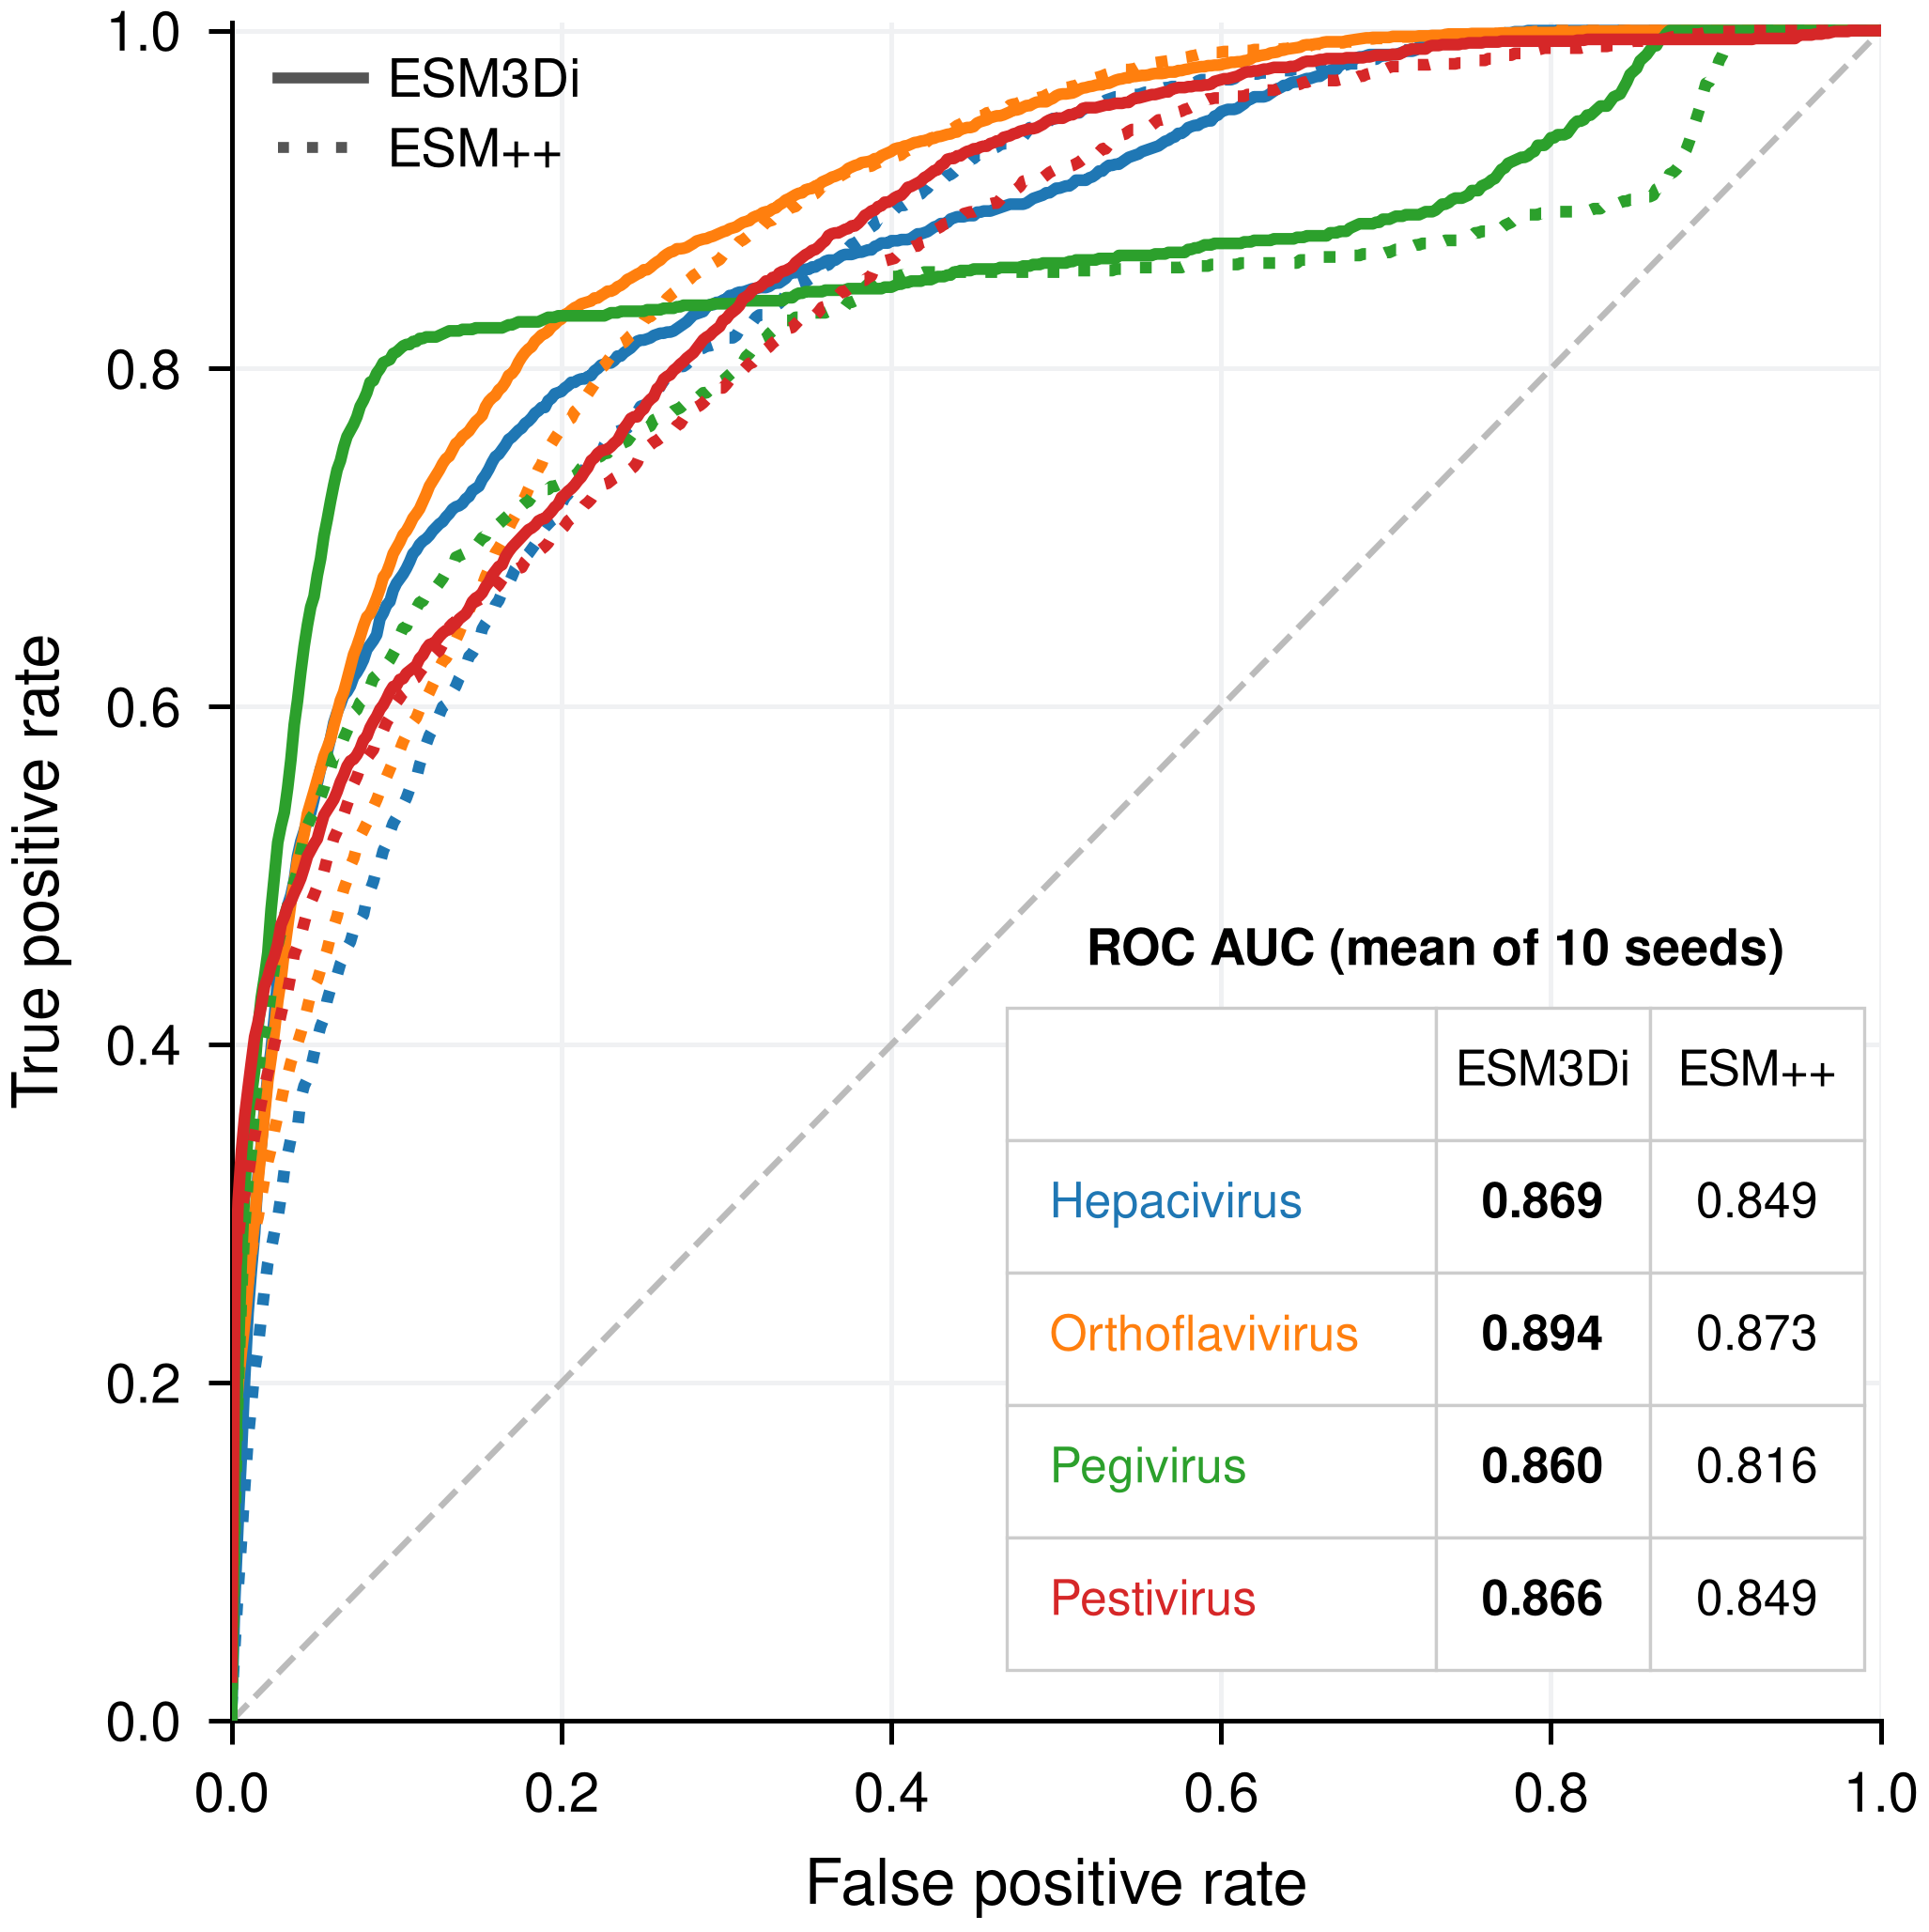

In [9]:
from IPython.display import Image, display
panel = RESULTS / "roc_curves_by_genus.png"
if panel.exists():
    print("Fig. 2d  (paper/figure2.ipynb picks this file up via PANEL_D_IMAGE)")
    display(Image(filename=str(panel), width=430))

paired_roc_auc.png


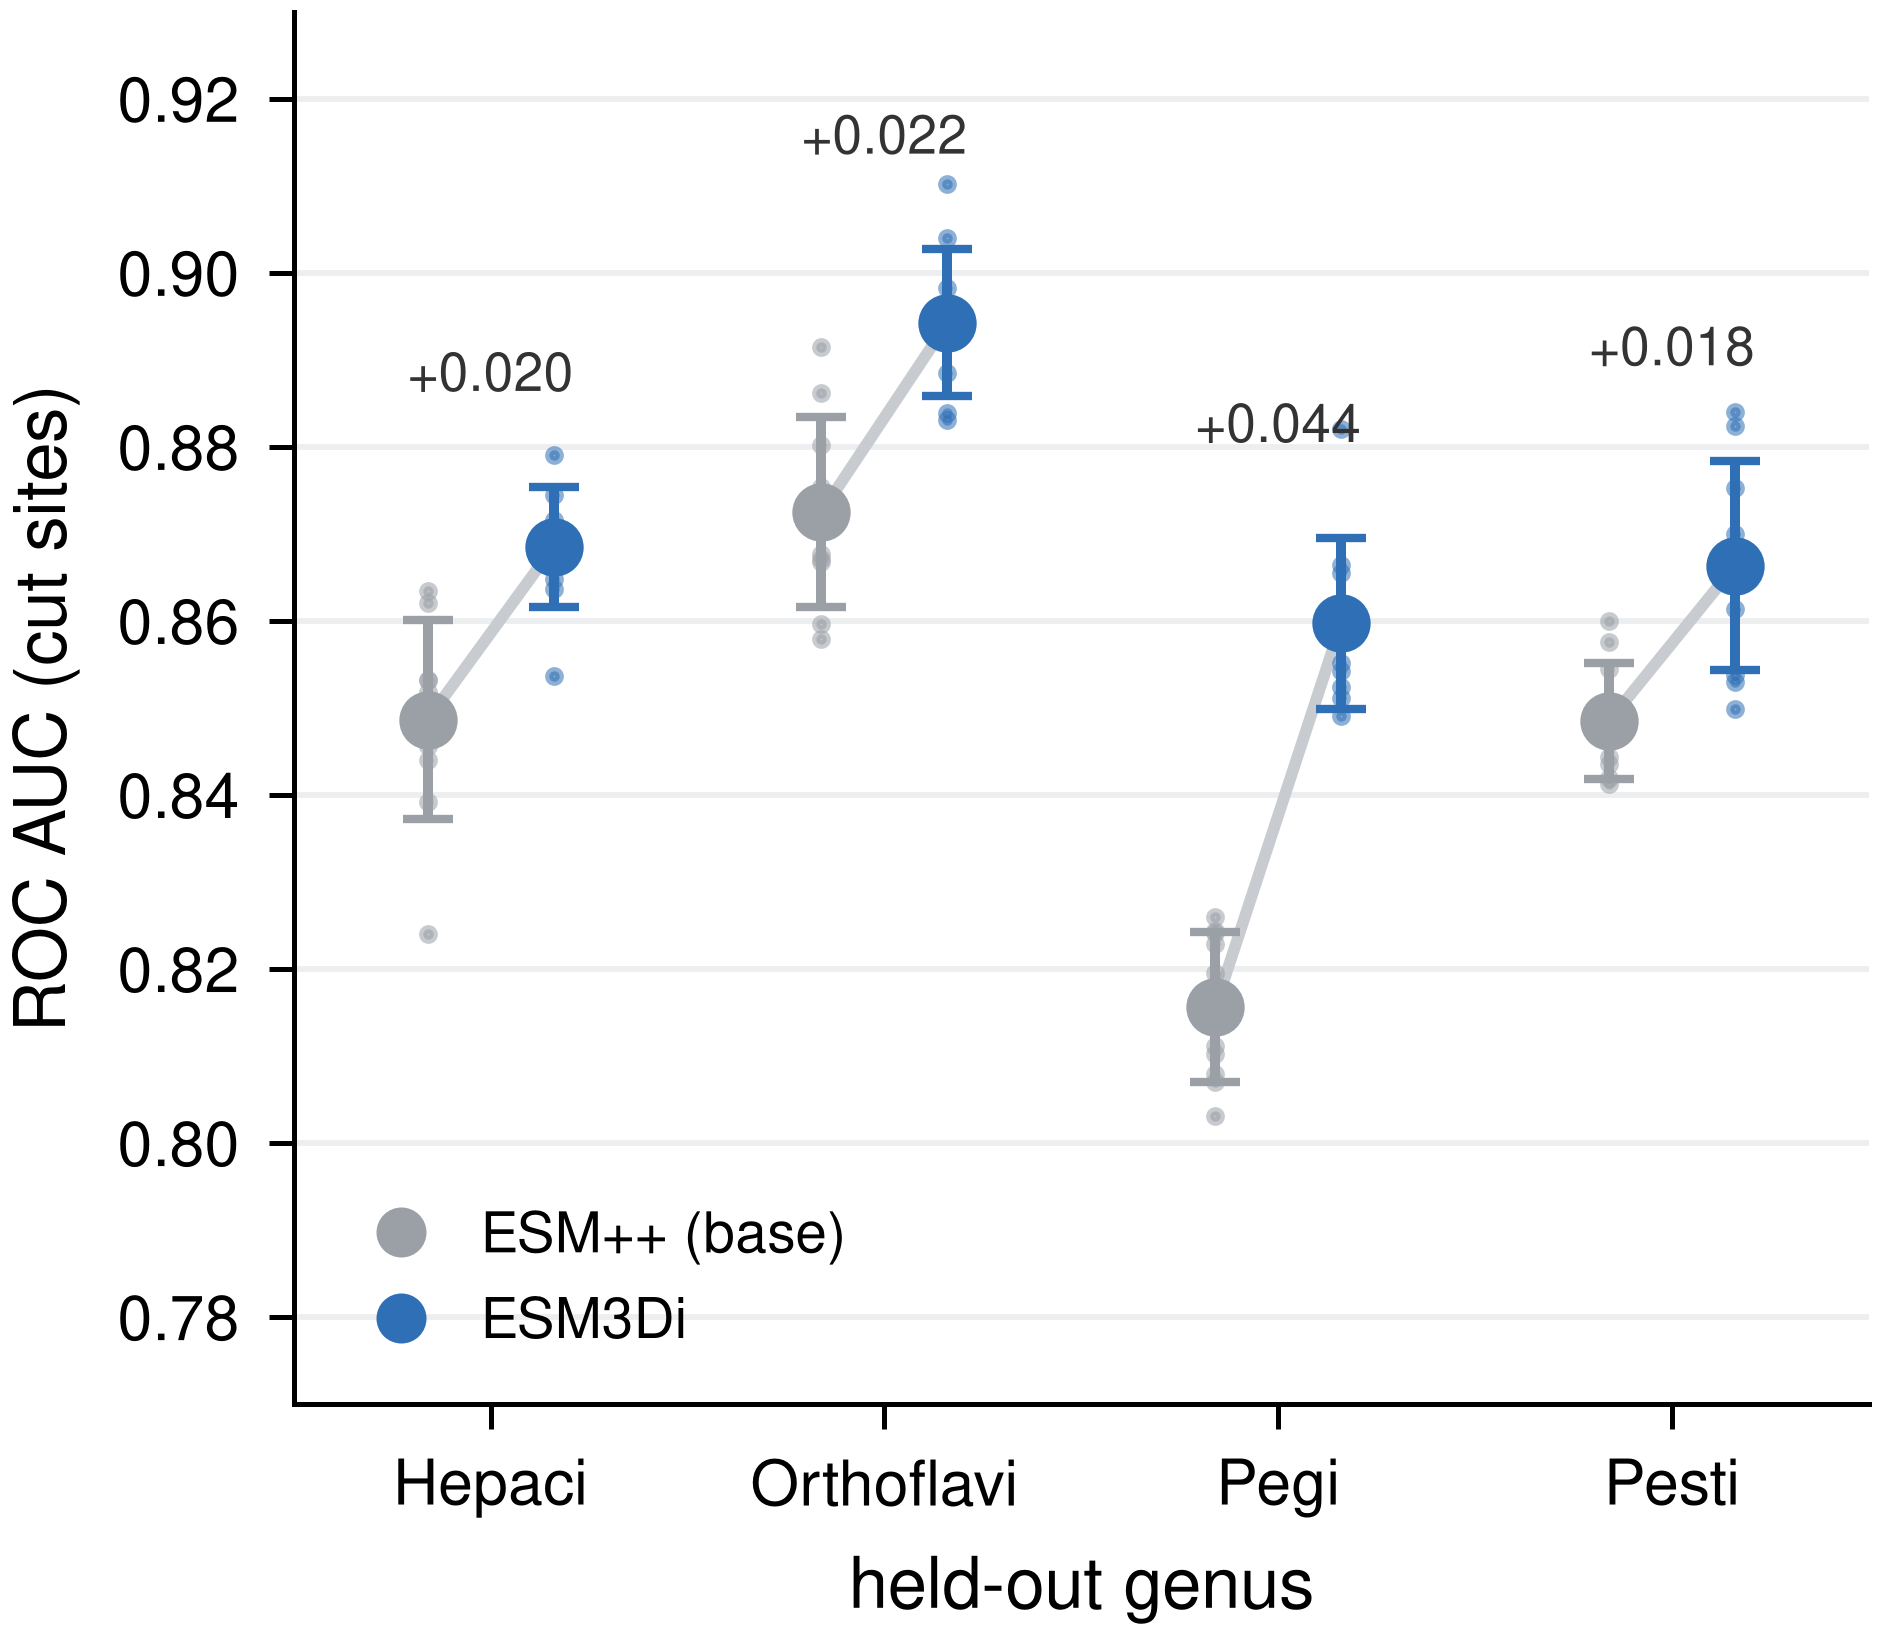

paired_delta.png


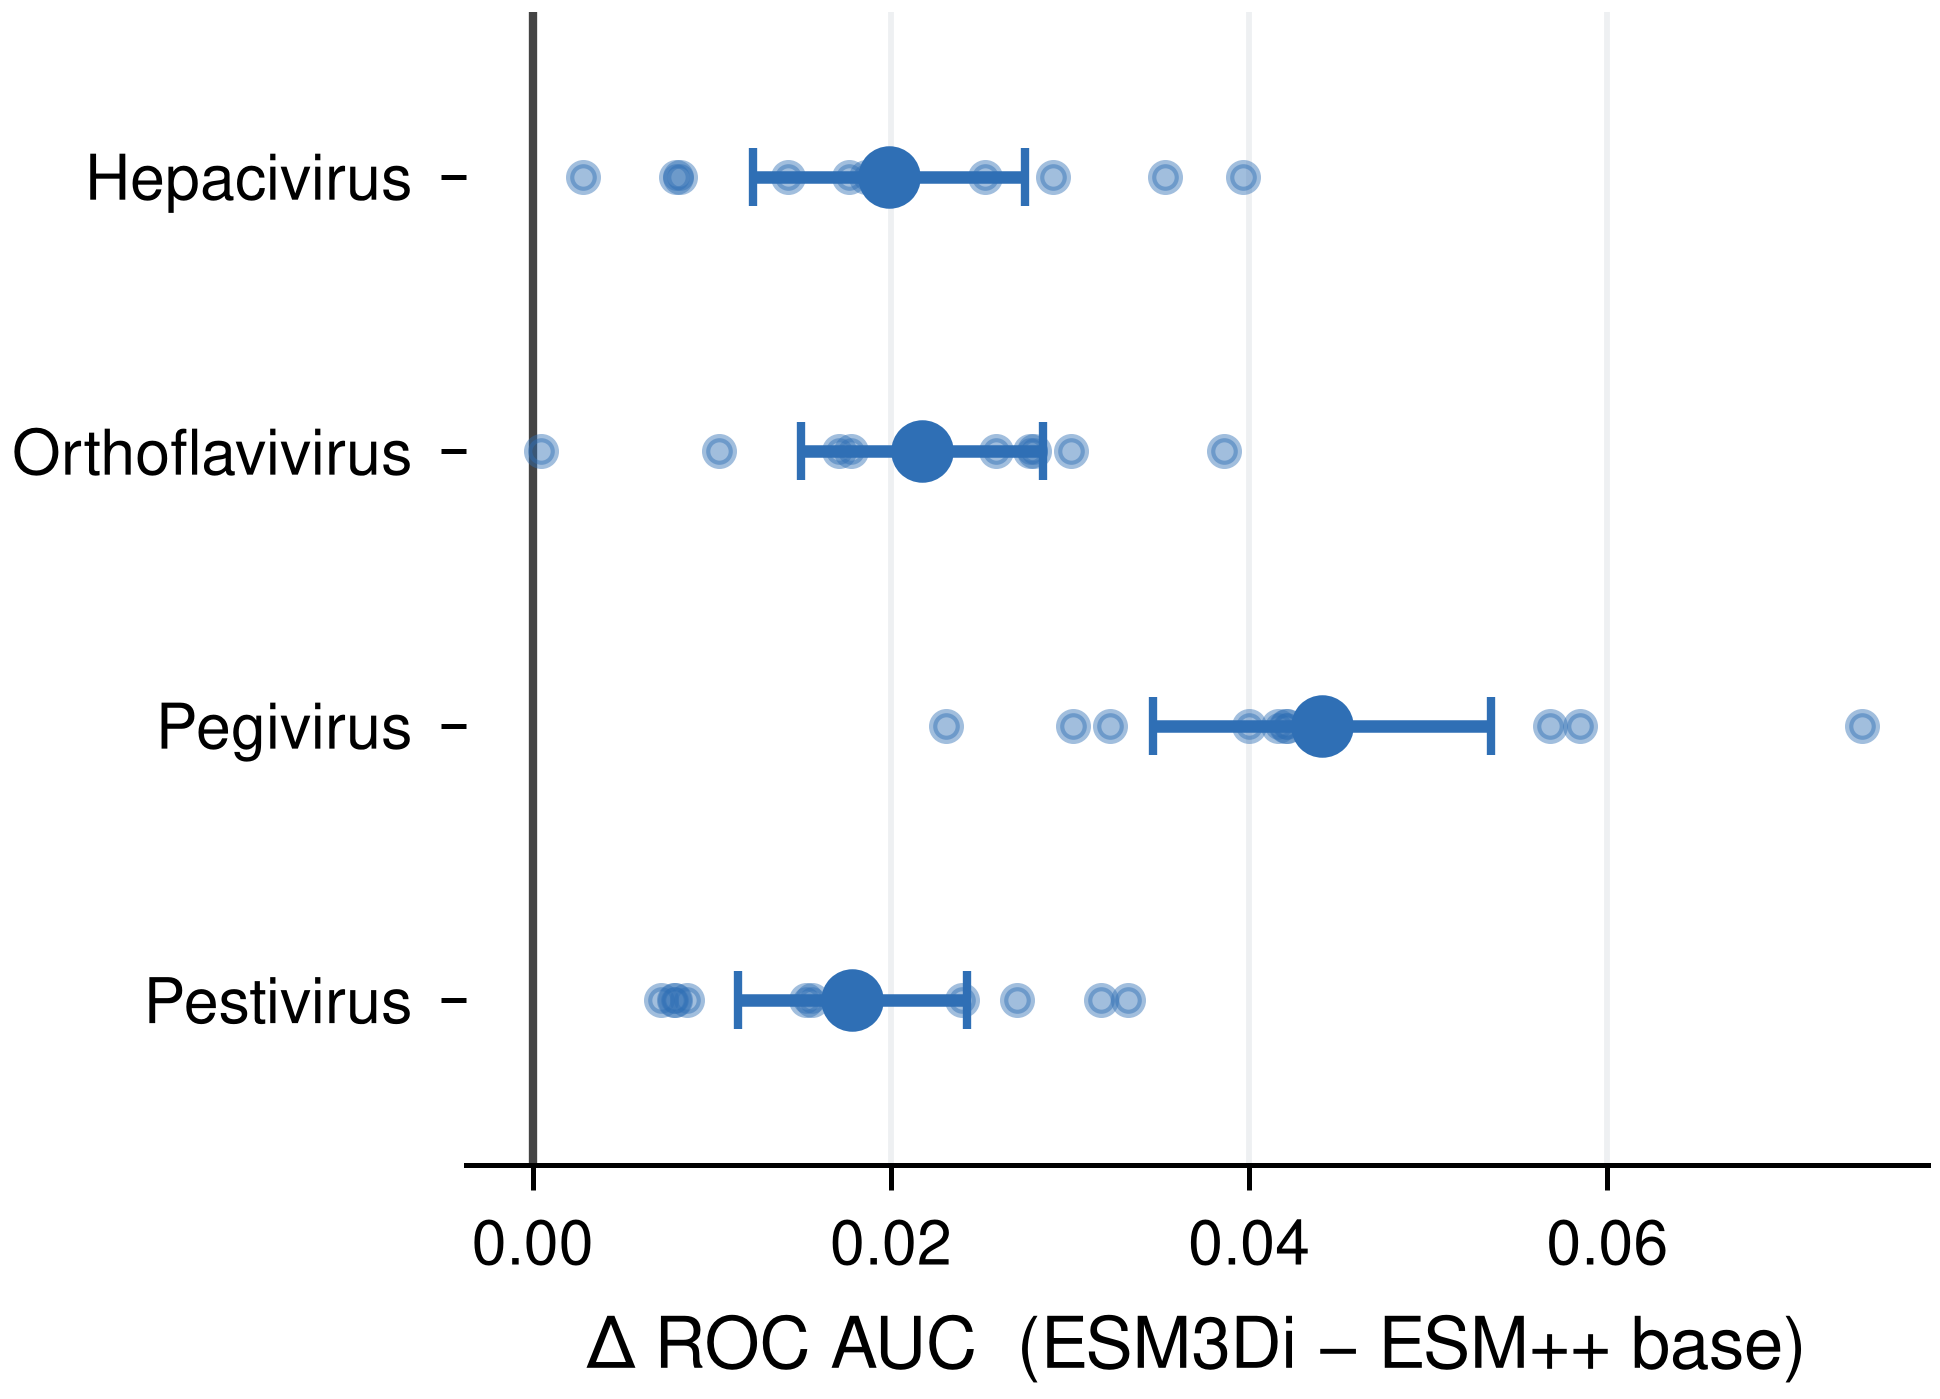

supp_fig_pick_distances.png


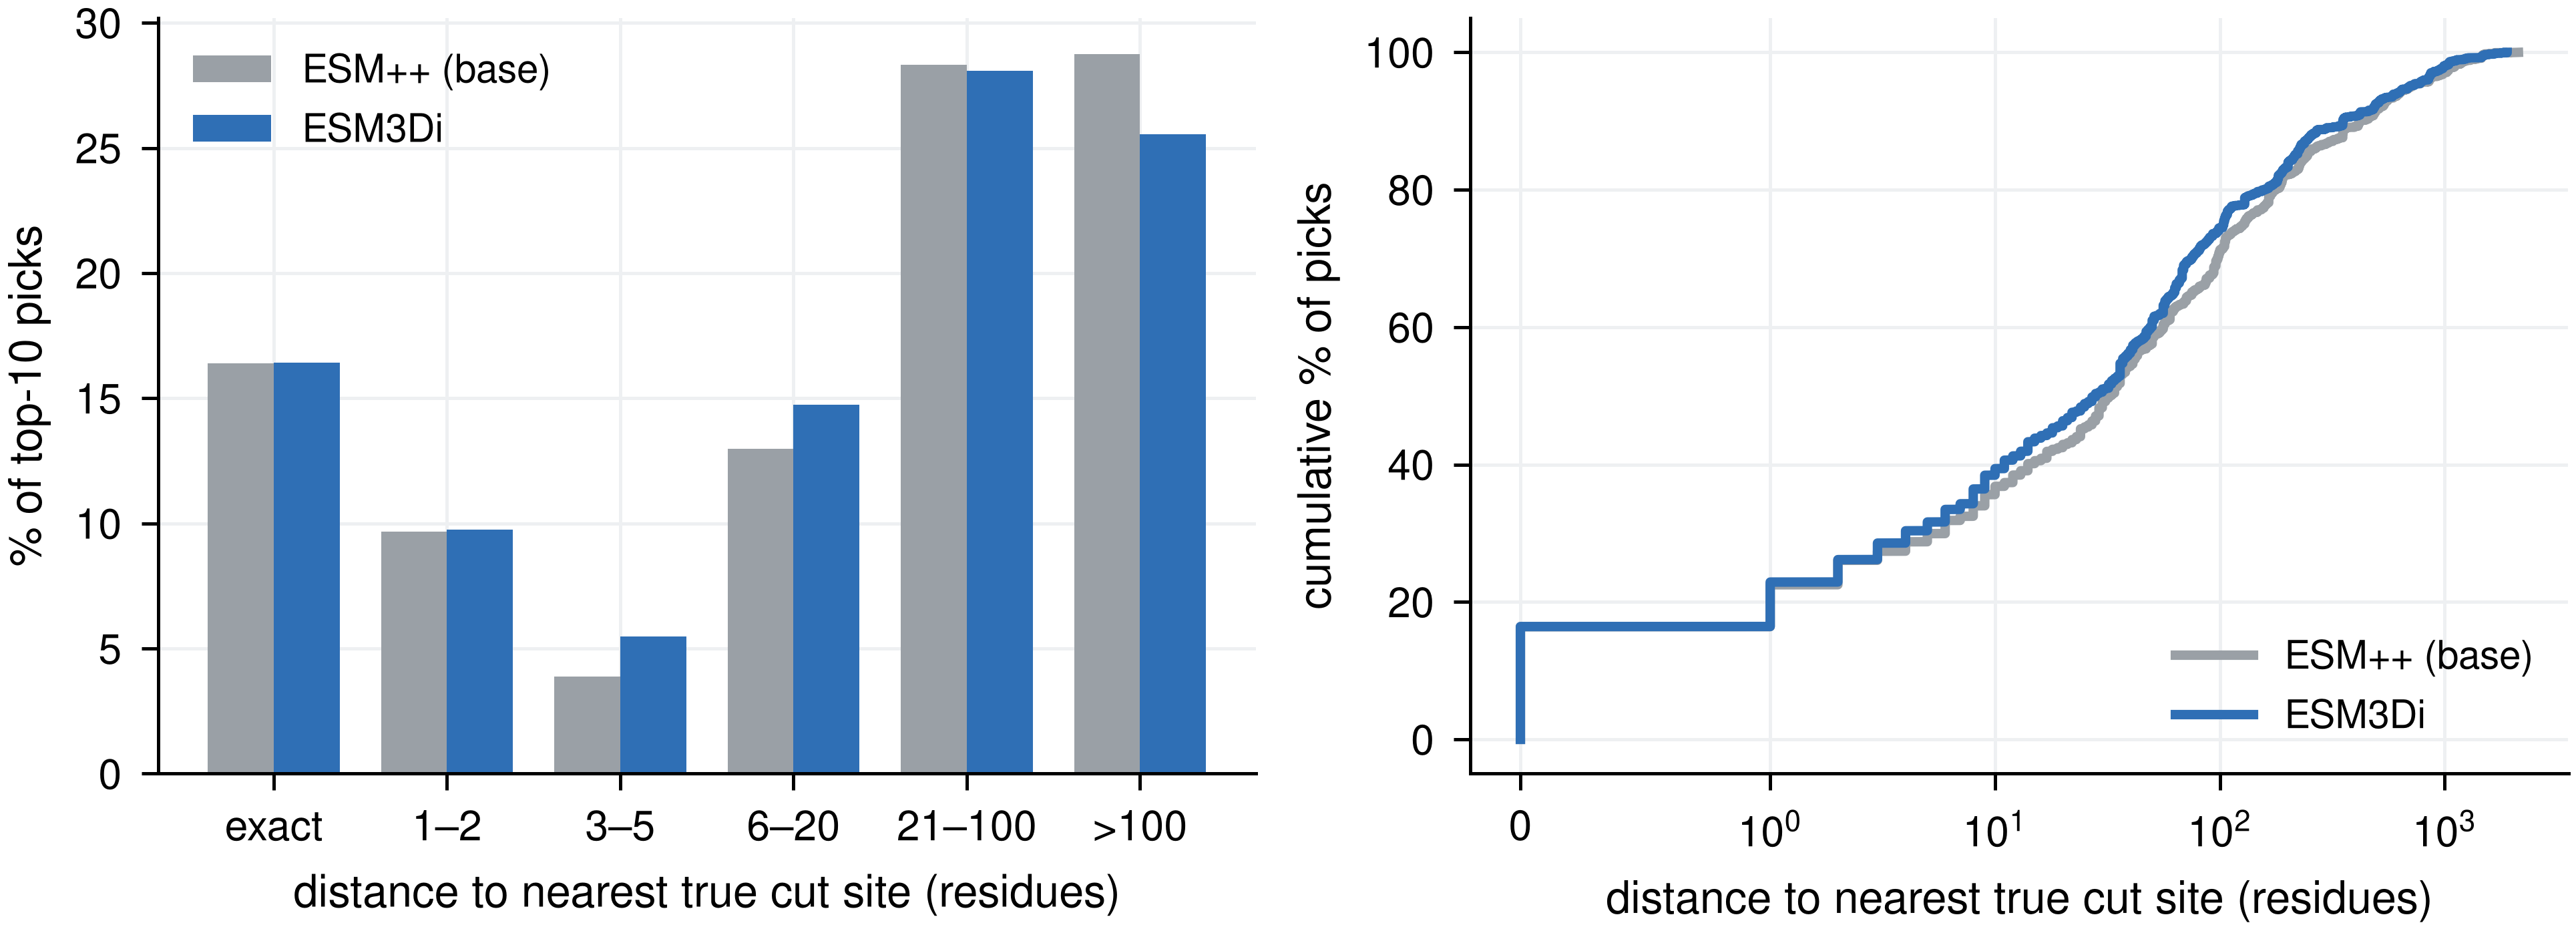

In [10]:
for name, width in (("paired_roc_auc.png", 390),
                    ("paired_delta.png", 400),
                    ("supp_fig_pick_distances.png", 720)):
    p = RESULTS / name
    if p.exists():
        print(name); display(Image(filename=str(p), width=width))

In [11]:
print("Supplementary table: all metrics, mean ± sd over seeds\n")
display(pd.read_csv(RESULTS / "supp_table_metrics.csv"))
dist = RESULTS / "supp_table_pick_distances.csv"
if dist.exists():
    print("\nDistance from each top-10 pick to the nearest annotated cut site\n")
    display(pd.read_csv(dist))

Supplementary table: all metrics, mean ± sd over seeds



,Held-out genus,Embeddings,n seq,n sites,ROC AUC,AP,AP ±2,AP ±5,top-10 recovery
0,Hepacivirus,ESM3Di,15,148,0.869 ± 0.007,0.055 ± 0.007,0.104 ± 0.006,0.127 ± 0.006,0.318 ± 0.026
1,Hepacivirus,ESM++ (base),15,148,0.849 ± 0.011,0.040 ± 0.002,0.099 ± 0.008,0.120 ± 0.008,0.237 ± 0.019
2,Orthoflavivirus,ESM3Di,31,347,0.894 ± 0.008,0.158 ± 0.013,0.162 ± 0.018,0.199 ± 0.018,0.283 ± 0.018
3,Orthoflavivirus,ESM++ (base),31,347,0.873 ± 0.011,0.167 ± 0.005,0.140 ± 0.009,0.156 ± 0.008,0.301 ± 0.020
4,Pegivirus,ESM3Di,21,112,0.860 ± 0.010,0.064 ± 0.015,0.081 ± 0.006,0.098 ± 0.006,0.462 ± 0.091
5,Pegivirus,ESM++ (base),21,112,0.816 ± 0.009,0.046 ± 0.006,0.077 ± 0.005,0.091 ± 0.006,0.361 ± 0.037
6,Pestivirus,ESM3Di,19,193,0.866 ± 0.012,0.182 ± 0.020,0.173 ± 0.014,0.171 ± 0.009,0.385 ± 0.028
7,Pestivirus,ESM++ (base),19,193,0.849 ± 0.007,0.245 ± 0.011,0.164 ± 0.013,0.150 ± 0.011,0.351 ± 0.017



Distance from each top-10 pick to the nearest annotated cut site



,distance (residues),ESM++ base (%),ESM3Di (%)
0,exact,16.4,16.4
1,1–2,9.7,9.7
2,3–5,3.9,5.5
3,6–20,13.0,14.7
4,21–100,28.3,28.1
5,>100,28.8,25.5
6,median distance,32.0,28.0
7,within 5 (%),29.9,31.6
8,within 20 (%),42.9,46.4
9,within 100 (%),71.2,74.5


### Supplementary table, as it appears in the brief communication

The same numbers in the layout used in the supplement: genus and fold sizes given once
per genus, with the second row carrying the base-model arm.

In [12]:
raw = pd.read_csv(RESULTS / "supp_table_metrics.csv")
paper = raw.copy()
blank = ["Held-out genus", "n seq", "n sites"]     # blank the repeat row of each genus
paper[blank] = paper[blank].astype(object)            # int columns cannot hold ""
paper.loc[paper.duplicated("Held-out genus"), blank] = ""
paper["Embeddings"] = paper["Embeddings"].str.replace(" (base)", "", regex=False)
paper.to_csv(RESULTS / "supp_table_metrics_formatted.csv", index=False)

display(paper.style.hide(axis="index"))
print("Cleavage sites are 0.28% of residues, so chance average precision is ~0.003.")

Held-out genus,Embeddings,n seq,n sites,ROC AUC,AP,AP ±2,AP ±5,top-10 recovery
Hepacivirus,ESM3Di,15,148,0.869 ± 0.007,0.055 ± 0.007,0.104 ± 0.006,0.127 ± 0.006,0.318 ± 0.026
,ESM++,,,0.849 ± 0.011,0.040 ± 0.002,0.099 ± 0.008,0.120 ± 0.008,0.237 ± 0.019
Orthoflavivirus,ESM3Di,31,347,0.894 ± 0.008,0.158 ± 0.013,0.162 ± 0.018,0.199 ± 0.018,0.283 ± 0.018
,ESM++,,,0.873 ± 0.011,0.167 ± 0.005,0.140 ± 0.009,0.156 ± 0.008,0.301 ± 0.020
Pegivirus,ESM3Di,21,112,0.860 ± 0.010,0.064 ± 0.015,0.081 ± 0.006,0.098 ± 0.006,0.462 ± 0.091
,ESM++,,,0.816 ± 0.009,0.046 ± 0.006,0.077 ± 0.005,0.091 ± 0.006,0.361 ± 0.037
Pestivirus,ESM3Di,19,193,0.866 ± 0.012,0.182 ± 0.020,0.173 ± 0.014,0.171 ± 0.009,0.385 ± 0.028
,ESM++,,,0.849 ± 0.007,0.245 ± 0.011,0.164 ± 0.013,0.150 ± 0.011,0.351 ± 0.017


Cleavage sites are 0.28% of residues, so chance average precision is ~0.003.


## Interpretation

ESM3Di embeddings separate cleavage sites better than non-fine-tuned ESM++ embeddings in
all four held-out genera on raw features too, so the conclusion does not depend on the
standardisation step used for Figure 2d. The gain is smaller here, and strict
single-residue average precision is flat to negative.

Limits worth stating with the result:

- The generalisation unit is the genus, so n = 4. The strength of the claim is the
  consistency across genera, not the size of the gap in any one of them.
- Four genera of one viral order, 800 annotated sites, labels transferred by homology
  rather than measured.
- This supports a representation-quality claim. It does not make the classifier a
  competitive cleavage-site predictor, and it is not presented as one.